# ¿Cuántas cajas se van a vender el próximo trimestre y cuánto vale pronosticar mejor?

Pronóstico de la demanda mensual de una embotelladora **ficticia** de Santa Cruz de la Sierra: cinco familias de productos, de octubre de 2019 a septiembre de 2026, en cajas.

| Pregunta | Respuesta |
|---|---|
| ¿Cuántas cajas se venderán entre octubre y diciembre de 2026? | Unas **2,02 millones de cajas**, 3,2% más que en el mismo trimestre de 2025. Gaseosas 2 L, la familia principal, venderá unas **744 mil cajas** (intervalo del 80%: entre 719 mil y 771 mil cajas). |
| ¿Qué método pronostica mejor? | Regresión en Gaseosas 2 L, Gaseosas 600 ml y Agua 2 L; SARIMA en Gaseosas 3 L; Holt-Winters en Jugos 1 L. El error (WAPE) baja de **7,5%** con el método base (copiar el mismo mes del año anterior) a **4,3%**: 42% menos. |
| ¿Cuánto vale pronosticar mejor? | El stock de seguridad baja en **26.215 cajas**: Bs 698.958 menos de inventario y **Bs 139.792 al año** de costo de mantenerlo. En diciembre de 2025, con el método base habrían faltado 14.879 cajas (Bs 272.807 de margen); con el mejor, 1.205 (Bs 24.432). |
| ¿Qué hacer primero? | **Usar la regresión en Gaseosas 2 L, Gaseosas 600 ml y Agua 2 L antes de planificar diciembre.** Concentran el 81% del ahorro (22.200 cajas menos de stock de seguridad). |

> Los datos se generan con `generar_datos.py` (semilla fija, así que los resultados se reproducen). Las fechas de Carnaval son las reales. Los números ilustran el método: no describen a ninguna empresa real.

In [1]:
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from matplotlib.ticker import FuncFormatter
from scipy.stats import norm
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX

import graficos as g

g.aplicar_estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.1f}")

DATOS, IMG, RESULTADOS = Path("datos"), Path("img"), Path("resultados")
IMG.mkdir(exist_ok=True)
RESULTADOS.mkdir(exist_ok=True)

ventas = pd.read_csv(DATOS / "ventas_mensuales.csv")
ventas["fecha"] = pd.to_datetime(ventas["periodo"], format="%Y-%m")
calendario = pd.read_csv(DATOS / "calendario_carnaval.csv", parse_dates=["sabado_carnaval", "martes_carnaval"])

FAMILIAS = ["Gaseosas 2 L", "Gaseosas 600 ml", "Gaseosas 3 L", "Agua 2 L", "Jugos 1 L"]
PRINCIPAL = "Gaseosas 2 L"
cajas = ventas.pivot(index="fecha", columns="familia", values="cajas")[FAMILIAS].asfreq("MS")

MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]

def mes_texto(fecha):
    return f"{MESES[fecha.month - 1]}-{fecha.year}"

def cantidad(valor):
    """Cantidad de cajas en palabras: 744 mil, 2,02 millones."""
    if valor >= 1_000_000:
        return f"{g.miles(valor / 1_000_000, 2)} millones"
    if valor >= 10_000:
        return f"{g.miles(valor / 1_000)} mil"
    return g.miles(valor)

def cajas_texto(valor):
    return cantidad(valor) + (" de cajas" if valor >= 1_000_000 else " cajas")

def signo(valor, decimales=1):
    if round(valor * 100, decimales) == 0:
        return g.porcentaje(0, decimales)
    return ("+" if valor > 0 else "−") + g.porcentaje(abs(valor), decimales)

def lista(elementos):
    elementos = list(elementos)
    return elementos[0] if len(elementos) == 1 else ", ".join(elementos[:-1]) + " y " + elementos[-1]

def en_porcentaje(tabla):
    """Pasa las columnas de proporciones a porcentaje, para leer las tablas más fácil."""
    return tabla * 100

print(f"{len(cajas)} meses, de {mes_texto(cajas.index[0])} a {mes_texto(cajas.index[-1])}, y {len(FAMILIAS)} familias")

84 meses, de oct-2019 a sep-2026, y 5 familias


## 1. Los datos

- `ventas_mensuales.csv`: una fila por mes y familia, con las cajas vendidas y el precio neto promedio por caja (Bs).
- `calendario_carnaval.csv`: el sábado y el martes de Carnaval de cada año, de 2020 a 2027. Son las fechas reales: el martes de Carnaval cae 47 días antes del domingo de Pascua.

Primero, cuánto pesa cada familia y cómo viene creciendo. Las columnas con `%` están en porcentaje.

In [2]:
ultimos_12 = cajas.iloc[-12:].sum()
anteriores_12 = cajas.iloc[-24:-12].sum()
hace_4_anios = cajas.iloc[-60:-48].sum()   # oct-2021 a sep-2022: ya sin el efecto de la pandemia

precio = ventas.pivot(index="fecha", columns="familia", values="precio_promedio_bs")[FAMILIAS]
precio_actual = precio.iloc[-12:].mean()
aumento_precio = precio.loc["2024-07":"2024-12"].mean() / precio.loc["2024-01":"2024-06"].mean() - 1
crecimiento_4_anios = (ultimos_12 / hace_4_anios) ** (1 / 4) - 1

familias = pd.DataFrame({
    "cajas_ultimos_12_meses": ultimos_12,
    "participacion_%": en_porcentaje(ultimos_12 / ultimos_12.sum()),
    "variacion_vs_12_meses_previos_%": en_porcentaje(ultimos_12 / anteriores_12 - 1),
    "crecimiento_anual_4_anios_%": en_porcentaje(crecimiento_4_anios),
    "precio_por_caja_bs": precio_actual,
    "aumento_precio_jul_2024_%": en_porcentaje(aumento_precio),
})
print(f"Total de los últimos 12 meses: {g.miles(ultimos_12.sum())} cajas "
      f"(unas {cajas_texto(ultimos_12.sum() / 12)} por mes)")
familias

Total de los últimos 12 meses: 6.909.215 cajas (unas 576 mil cajas por mes)


,cajas_ultimos_12_meses,participacion_%,variacion_vs_12_meses_previos_%,crecimiento_anual_4_anios_%,precio_por_caja_bs,aumento_precio_jul_2024_%
familia,,,,,,
Gaseosas 2 L,2627669,38.0,3.6,2.9,52.7,10.1
Gaseosas 600 ml,1760211,25.5,8.2,4.6,46.1,9.5
Gaseosas 3 L,843042,12.2,0.5,-0.5,50.7,10.0
Agua 2 L,1306900,18.9,10.4,12.1,32.4,7.9
Jugos 1 L,371393,5.4,-3.6,-5.4,87.4,11.6


Agua 2 L es la que más crece (12% al año en los últimos 4 años) y Jugos 1 L la que más cae. Gaseosas 3 L está estancada. En julio de 2024 subió el precio de lista entre 8% y 12%, según la familia.

## 2. Descomposición: tendencia, estacionalidad y lo que queda

La descomposición STL separa la serie en tres partes:

- **Tendencia:** hacia dónde va la venta, sin los altibajos del año.
- **Estacionalidad:** el patrón que se repite cada año.
- **Residuo:** lo que no explican las dos anteriores, como una caída puntual o un mes raro.

Se aplica al logaritmo de las ventas para que los efectos sean porcentuales: diciembre suma un porcentaje de la venta, no una cantidad fija de cajas. La versión robusta evita que un mes atípico, como los de la pandemia, deforme la tendencia.

In [3]:
PANDEMIA = pd.to_datetime(["2020-04-01", "2020-05-01", "2020-06-01"])

def descomponer(serie):
    return STL(np.log(serie), period=12, robust=True).fit()

stl = descomponer(cajas[PRINCIPAL])
residuo = np.exp(stl.resid) - 1
cerca = (residuo.drop(PANDEMIA).abs() <= 0.05).mean()
print(f"{PRINCIPAL}: crecimiento anual de los últimos 4 años {g.porcentaje(crecimiento_4_anios[PRINCIPAL], 1)}")
print(f"Fuera de la pandemia, el {g.porcentaje(cerca)} de los meses queda a menos de 5% de lo esperado")

mayores = residuo.reindex(residuo.abs().sort_values(ascending=False).index).head(5)
pd.DataFrame({"mes": [mes_texto(f) for f in mayores.index],
              "diferencia_vs_lo_esperado_%": en_porcentaje(mayores.values)}).set_index("mes")

Gaseosas 2 L: crecimiento anual de los últimos 4 años 2,9%
Fuera de la pandemia, el 93% de los meses queda a menos de 5% de lo esperado


,diferencia_vs_lo_esperado_%
mes,
abr-2020,-33.9
may-2020,-25.2
oct-2020,-18.0
mar-2025,15.9
feb-2022,-8.2


- Los dos mayores desvíos son **abril y mayo de 2020**: la caída de la pandemia. En junio la venta ya estaba casi normal.
- **Marzo de 2025** vendió 16% más de lo esperado: ese año el sábado de Carnaval fue el 1 de marzo.
- **Octubre de 2020** fue un mes flojo sin una causa en los datos. Se deja como está.
- El aumento de precio de julio de 2024 no deja una marca clara: la baja fue leve y se confunde con el ruido de un mes a otro.

PosixPath('img/01_descomposicion.png')

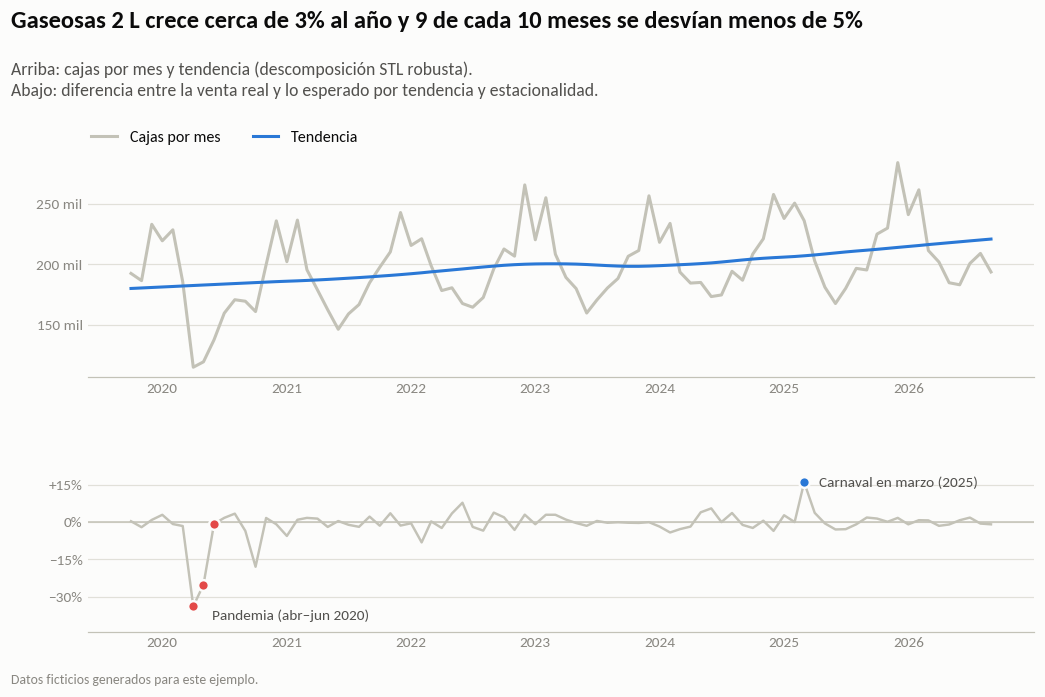

In [4]:
def eje_cajas(ax):
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{g.miles(v / 1000)} mil"))
    ax.grid(axis="y")
    ax.tick_params(axis="y", colors=g.TENUE, labelsize=10)

def eje_anios(ax, desde, hasta):
    anios = pd.date_range(desde, hasta, freq="YS")
    ax.set_xticks(anios.to_numpy())
    ax.set_xticklabels([str(a.year) for a in anios])
    ax.spines["bottom"].set_color(g.EJE)

def marcador(ax, x, y, color, tamanio=8):
    ax.plot(x, y, "o", color=color, markersize=tamanio, markeredgecolor=g.SUPERFICIE, markeredgewidth=1.6, zorder=5)

fechas = cajas.index.to_numpy()
fig, ax = g.figura(alto=6.6, ejes=(0.09, 0.45, 0.86, 0.31))
ax_residuo = fig.add_axes((0.09, 0.10, 0.86, 0.24))
g.encabezado(fig, f"{PRINCIPAL} crece cerca de {g.porcentaje(crecimiento_4_anios[PRINCIPAL])} al año y "
                  f"{round(cerca * 10)} de cada 10 meses se desvían menos de 5%",
             "Arriba: cajas por mes y tendencia (descomposición STL robusta).\n"
             "Abajo: diferencia entre la venta real y lo esperado por tendencia y estacionalidad.")
ax.plot(fechas, cajas[PRINCIPAL], color=g.GRIS, linewidth=2, label="Cajas por mes")
ax.plot(fechas, np.exp(stl.trend), color=g.AZUL, linewidth=2, label="Tendencia")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.81), ncols=2, fontsize=10.5, handlelength=1.6)
eje_cajas(ax)
eje_anios(ax, "2020-01-01", "2026-01-01")

ax_residuo.axhline(0, color=g.EJE, linewidth=1)
ax_residuo.plot(fechas, residuo, color=g.GRIS, linewidth=1.6)
for fecha in PANDEMIA:
    marcador(ax_residuo, fecha, residuo[fecha], g.ROJO, tamanio=7)
ax_residuo.annotate("Pandemia (abr–jun 2020)", (PANDEMIA[0], residuo[PANDEMIA[0]]), xytext=(12, -6),
                    textcoords="offset points", fontsize=10, color=g.TINTA_2, va="center")
marzo_2025 = pd.Timestamp("2025-03-01")
marcador(ax_residuo, marzo_2025, residuo[marzo_2025], g.AZUL, tamanio=7)
ax_residuo.annotate("Carnaval en marzo (2025)", (marzo_2025, residuo[marzo_2025]), xytext=(10, 0),
                    textcoords="offset points", fontsize=10, color=g.TINTA_2, va="center")
ax_residuo.set_ylim(-0.44, 0.26)
ax_residuo.set_yticks([-0.3, -0.15, 0, 0.15])
ax_residuo.yaxis.set_major_formatter(FuncFormatter(lambda v, _: signo(v, 0)))
ax_residuo.grid(axis="y")
ax_residuo.tick_params(axis="y", colors=g.TENUE, labelsize=10)
eje_anios(ax_residuo, "2020-01-01", "2026-01-01")
g.pie(fig)
g.guardar(fig, IMG / "01_descomposicion.png")

### Perfil estacional y Carnaval

El perfil estacional dice cuánto vende cada mes frente a un mes promedio (en %). Se calcula para cada familia con la misma descomposición.

In [5]:
perfil = pd.DataFrame({
    familia: np.exp(descomponer(cajas[familia]).seasonal.groupby(cajas.index.month).mean()) - 1
    for familia in FAMILIAS})
perfil.index = MESES
en_porcentaje(perfil.T)

,ene,feb,mar,abr,may,jun,jul,ago,sep,oct,nov,dic
Gaseosas 2 L,13.5,23.7,0.7,-5.9,-12.0,-20.0,-13.6,-8.2,-6.8,5.2,6.7,29.2
Gaseosas 600 ml,12.3,12.9,2.6,-3.8,-13.4,-21.2,-17.2,-9.1,-2.7,7.0,12.3,36.9
Gaseosas 3 L,18.3,31.2,2.6,-4.2,-10.8,-24.7,-21.4,-11.8,-7.0,2.9,4.6,41.6
Agua 2 L,18.4,17.3,-1.1,-5.4,-17.8,-18.9,-17.2,-10.4,-1.9,3.1,12.5,37.3
Jugos 1 L,7.7,4.9,-2.7,-5.1,-6.4,-7.6,-10.9,-4.6,0.9,3.1,4.9,21.8


Diciembre es el mes más alto en todas las familias: calor, fiestas y aguinaldo. Junio y julio son los más bajos (en Agua, también mayo). Gaseosas 3 L es la más estacional y Jugos 1 L, la menos.

Febrero sale alto también por **Carnaval**, que casi siempre cae en febrero. Pero no siempre: en 2025 el sábado de Carnaval fue el 1 de marzo. Para verlo, se compara febrero y marzo de cada año con su tendencia.

In [6]:
sobre_tendencia = np.exp(np.log(cajas[PRINCIPAL]) - stl.trend) - 1
carnaval_anual = calendario.set_index("anio")
anios = list(range(2020, 2027))
feb_mar = pd.DataFrame({
    "sabado_carnaval": [carnaval_anual.loc[a, "sabado_carnaval"].date() for a in anios],
    "febrero_vs_tendencia_%": [100 * sobre_tendencia[pd.Timestamp(a, 2, 1)] for a in anios],
    "marzo_vs_tendencia_%": [100 * sobre_tendencia[pd.Timestamp(a, 3, 1)] for a in anios],
}, index=anios)
marzo_sin_carnaval = feb_mar.loc[feb_mar.index != 2025, "marzo_vs_tendencia_%"] / 100
marzo_con_carnaval = feb_mar.loc[2025, "marzo_vs_tendencia_%"] / 100
print(f"Marzo sin Carnaval: entre {signo(marzo_sin_carnaval.min(), 0)} y {signo(marzo_sin_carnaval.max(), 0)} "
      f"frente a la tendencia. Marzo de 2025, con Carnaval: {signo(marzo_con_carnaval, 0)}")
feb_mar

Marzo sin Carnaval: entre −3% y +5% frente a la tendencia. Marzo de 2025, con Carnaval: +14%


,sabado_carnaval,febrero_vs_tendencia_%,marzo_vs_tendencia_%
2020,2020-02-22,25.9,1.9
2021,2021-02-13,27.1,4.7
2022,2022-02-26,14.7,2.6
2023,2023-02-18,27.4,4.0
2024,2024-02-10,17.4,-3.1
2025,2025-03-01,21.5,14.1
2026,2026-02-14,21.5,-2.3


PosixPath('img/02_perfil_estacional.png')

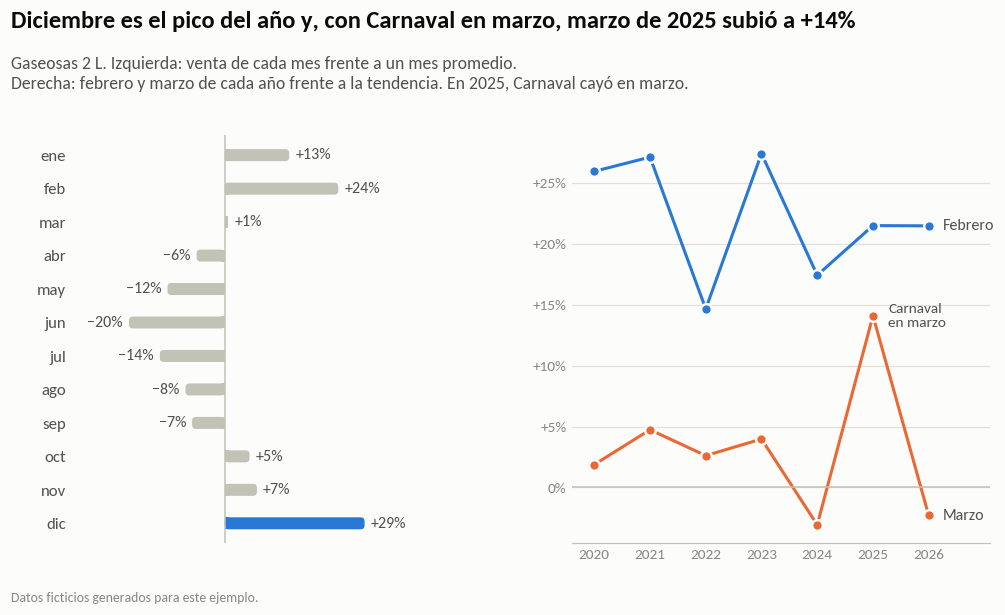

In [7]:
perfil_principal = perfil[PRINCIPAL]
fig, ax = g.figura(alto=5.8, ejes=(0.075, 0.12, 0.33, 0.64))
ax_carnaval = fig.add_axes((0.53, 0.12, 0.38, 0.64))
g.encabezado(fig, f"Diciembre es el pico del año y, con Carnaval en marzo, marzo de 2025 subió a {signo(marzo_con_carnaval, 0)}",
             f"{PRINCIPAL}. Izquierda: venta de cada mes frente a un mes promedio.\n"
             "Derecha: febrero y marzo de cada año frente a la tendencia. En 2025, Carnaval cayó en marzo.")
colores = [g.AZUL if mes == "dic" else g.GRIS for mes in MESES]
g.barras_horizontales(ax, MESES, perfil_principal.values, colores,
                      textos=[signo(v, 0) for v in perfil_principal.values], grosor_px=12,
                      x_min=perfil_principal.min() * 1.6, x_max=perfil_principal.max() * 1.5)
ax.axvline(0, color=g.EJE, linewidth=1)

x = np.array(anios)
for columna, color, nombre in [("febrero_vs_tendencia_%", g.AZUL, "Febrero"), ("marzo_vs_tendencia_%", g.CATEGORICOS[1], "Marzo")]:
    valores = feb_mar[columna].to_numpy() / 100
    ax_carnaval.plot(x, valores, color=color, linewidth=2)
    for xi, yi in zip(x, valores):
        marcador(ax_carnaval, xi, yi, color, tamanio=7)
    ax_carnaval.text(x[-1] + 0.25, valores[-1], nombre, fontsize=10.5, color=g.TINTA_2, va="center")
ax_carnaval.annotate("Carnaval\nen marzo", (2025, marzo_con_carnaval), xytext=(10, 0), textcoords="offset points",
                     fontsize=10, color=g.TINTA_2, va="center", linespacing=1.2)
ax_carnaval.axhline(0, color=g.EJE, linewidth=1)
ax_carnaval.set_xticks(x)
ax_carnaval.set_xlim(x[0] - 0.4, x[-1] + 1.1)
ax_carnaval.yaxis.set_major_formatter(FuncFormatter(lambda v, _: signo(v, 0)))
ax_carnaval.grid(axis="y")
ax_carnaval.tick_params(axis="y", colors=g.TENUE, labelsize=10)
ax_carnaval.spines["bottom"].set_color(g.EJE)
g.pie(fig)
g.guardar(fig, IMG / "02_perfil_estacional.png")

Los años en que Carnaval cayó en febrero, marzo quedó cerca de su tendencia. En 2025, con Carnaval en marzo, marzo saltó. Febrero de 2025 igual quedó alto: además del calendario, hay ruido. Un método que copia el año anterior arrastra ese marzo de 2025 a marzo de 2026, que ya no tuvo Carnaval.

## 3. La caída de la pandemia

Abril, mayo y junio de 2020 son atípicos. Si se dejan como están, los métodos los toman como parte del patrón y los repiten. Se reemplazan por lo esperado según la tendencia y la estacionalidad de la descomposición. Esa limpieza se hace dentro de cada ventana de entrenamiento, solo con los datos disponibles en ese momento.

In [8]:
def limpiar(log):
    """Reemplaza los meses de la pandemia por tendencia + estacionalidad (en logaritmo)."""
    stl = STL(log, period=12, robust=True).fit()
    log = log.copy()
    meses = log.index.intersection(PANDEMIA)
    log[meses] = (stl.trend + stl.seasonal)[meses]
    return log

limpia = np.exp(limpiar(np.log(cajas[PRINCIPAL])))
pd.DataFrame({"real": cajas.loc[PANDEMIA, PRINCIPAL], "reemplazo": limpia[PANDEMIA].round().astype(int)},
             index=PANDEMIA.strftime("%Y-%m"))

,real,reemplazo
2020-04,114509,173135
2020-05,118998,159012
2020-06,137319,138361


## 4. Cuatro métodos

Todos trabajan sobre el logaritmo de las ventas ya limpias.

| Método | Qué hace | Cuándo funciona bien |
|---|---|---|
| **Naive estacional** (método base) | Copia el mismo mes del año anterior. | Cuando las ventas no crecen y el calendario no cambia. |
| **Holt-Winters** | Suavizado exponencial: un nivel, una tendencia amortiguada y un factor por mes, que se actualizan con cada dato nuevo. | Cuando la tendencia cambia de a poco. |
| **SARIMA** | Modelo (0,1,1)(0,1,1)<sub>12</sub>, el clásico "modelo aerolínea": trabaja con la variación contra el mes anterior y contra el mismo mes del año anterior. | Series con tendencia y estacionalidad estables. |
| **Regresión** | Tendencia recta + un efecto por mes + Carnaval (vale 1 en el mes del sábado de Carnaval). | Cuando el calendario importa, porque usa las fechas reales de cada año. |

Cada método devuelve un pronóstico central y trayectorias simuladas. Con las trayectorias se arman los intervalos del 80%: el 10% más bajo y el 10% más alto quedan afuera.

**Avisos de statsmodels.** El backtest ajusta 210 modelos. Si el optimizador de alguno no converge del todo, statsmodels imprime un aviso en cada ajuste y el notebook se llena de texto repetido. Por eso los avisos se registran y se cuentan en lugar de imprimirse, y el total se informa al final del backtest. Para SARIMA se usan valores iniciales explícitos y el optimizador Nelder-Mead: con los valores por defecto, algunos ajustes no convergían.

In [9]:
INICIO = cajas.index[0]
MESES_CARNAVAL = pd.DatetimeIndex(calendario["sabado_carnaval"]).to_period("M").to_timestamp()

def variables(fechas):
    """Variables de la regresión: tendencia, un indicador por mes (enero es la base) y Carnaval."""
    X = pd.DataFrame({"constante": 1.0,
                      "tendencia": (fechas.year - INICIO.year) * 12 + fechas.month - INICIO.month}, index=fechas)
    for mes in range(2, 13):
        X[f"mes_{mes}"] = (fechas.month == mes).astype(float)
    X["carnaval"] = fechas.isin(MESES_CARNAVAL).astype(float)
    return X

def fechas_futuras(serie, h):
    return pd.date_range(serie.index[-1] + pd.offsets.MonthBegin(), periods=h, freq="MS")

# Cada método recibe el logaritmo de la serie y devuelve (pronóstico, función que simula trayectorias)
def naive_estacional(log, h):
    pronostico = log.iloc[-12:].to_numpy()[:h]
    desvio = np.sqrt((log.diff(12).dropna().iloc[-36:] ** 2).mean())
    return pronostico, lambda n, rng: pronostico + rng.normal(0, desvio, size=(n, h))

def holt_winters(log, h):
    ajuste = ExponentialSmoothing(log, trend="add", damped_trend=True, seasonal="add", seasonal_periods=12,
                                  initialization_method="estimated").fit()
    simular = lambda n, rng: ajuste.simulate(h, repetitions=n, error="add", anchor="end", rng=rng).to_numpy().T
    return ajuste.forecast(h).to_numpy(), simular

def sarima(log, h):
    modelo = SARIMAX(log, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12))
    inicio = [-0.5, -0.5, log.diff().diff(12).var()]
    ajuste = modelo.fit(start_params=inicio, method="nm", maxiter=1000, disp=False)
    simular = lambda n, rng: np.asarray(ajuste.simulate(h, repetitions=n, anchor="end", rng=rng)).reshape(h, n).T
    return ajuste.forecast(h).to_numpy(), simular

def regresion(log, h):
    ajuste = sm.OLS(log.to_numpy(), variables(log.index).to_numpy()).fit()
    X_futuro = variables(fechas_futuras(log, h)).to_numpy()
    pronostico = X_futuro @ ajuste.params
    covarianza = X_futuro @ ajuste.cov_params() @ X_futuro.T + ajuste.scale * np.eye(h)
    return pronostico, lambda n, rng: rng.multivariate_normal(pronostico, covarianza, size=n)

METODOS = {"Naive estacional": naive_estacional, "Holt-Winters": holt_winters,
           "SARIMA": sarima, "Regresión": regresion}
AVISOS = Counter()

def pronosticar(metodo, serie, h, simulaciones=1000, semilla=0):
    """Pronóstico en cajas de los h meses siguientes y sus trayectorias simuladas (una por columna)."""
    log = limpiar(np.log(serie))
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        pronostico, simular = METODOS[metodo](log, h)
        trayectorias = np.exp(simular(simulaciones, np.random.default_rng(semilla)))
    AVISOS.update(aviso.category.__name__ for aviso in avisos)
    fechas = fechas_futuras(serie, h)
    return pd.Series(np.exp(pronostico), index=fechas), pd.DataFrame(trayectorias.T, index=fechas)

### ¿Cuánto suma Carnaval?

La regresión estima cuánto suma Carnaval al mes en que cae. Se ajusta con toda la historia de cada familia.

In [10]:
efecto = {}
for familia in FAMILIAS:
    log = limpiar(np.log(cajas[familia]))
    ajuste = sm.OLS(log, variables(log.index)).fit()
    b, error_estandar = ajuste.params["carnaval"], ajuste.bse["carnaval"]
    efecto[familia] = {"efecto_carnaval_%": np.exp(b) - 1,
                       "minimo_95_%": np.exp(b - 1.96 * error_estandar) - 1,
                       "maximo_95_%": np.exp(b + 1.96 * error_estandar) - 1}
en_porcentaje(pd.DataFrame(efecto).T)

,efecto_carnaval_%,minimo_95_%,maximo_95_%
Gaseosas 2 L,6.5,0.0,13.4
Gaseosas 600 ml,7.5,-0.9,16.7
Gaseosas 3 L,14.7,4.6,25.8
Agua 2 L,-1.9,-9.7,6.6
Jugos 1 L,-0.8,-12.3,12.1


Carnaval suma cerca de 7% en Gaseosas 2 L y 15% en Gaseosas 3 L, la familia de las fiestas. En Agua y Jugos no se distingue de cero. Los intervalos son anchos porque la única forma de separar Carnaval del resto de febrero es un año en que cayó en marzo, y entre 2020 y 2026 eso pasó una sola vez.

## 5. Backtest de origen móvil

La prueba simula lo que habría pasado si cada método se hubiera usado en el último año:

1. Se "vuelve" a un mes del pasado (el **origen**) y se entrena solo con los datos hasta ese mes.
2. Se pronostican los 3 meses siguientes (horizontes 1, 2 y 3).
3. Se compara con lo que realmente se vendió y se avanza un mes.

Los orígenes van de julio de 2025 a agosto de 2026, así cada horizonte se evalúa sobre los mismos 12 meses: **octubre de 2025 a septiembre de 2026**.

Métricas:
- **WAPE** = suma de los errores absolutos / suma de las ventas reales. Es el error promedio en porcentaje, pesado por volumen.
- **Sesgo** = suma de (pronóstico − real) / suma de las ventas reales. Si es negativo, el método se queda corto y hay riesgo de quiebre de stock; si es positivo, sobra inventario.

In [11]:
PRUEBA = pd.date_range("2025-10-01", "2026-09-01", freq="MS")
HORIZONTES = 3
ORIGENES = pd.date_range(PRUEBA[0] - pd.DateOffset(months=HORIZONTES), PRUEBA[-1] - pd.DateOffset(months=1), freq="MS")

filas = []
for familia in FAMILIAS:
    for origen in ORIGENES:
        historia = cajas.loc[:origen, familia]
        for metodo in METODOS:
            pronostico, trayectorias = pronosticar(metodo, historia, HORIZONTES)
            inferior, superior = trayectorias.quantile(0.10, axis=1), trayectorias.quantile(0.90, axis=1)
            for h, objetivo in enumerate(pronostico.index, start=1):
                if objetivo in PRUEBA:
                    filas.append(dict(familia=familia, metodo=metodo, origen=origen, objetivo=objetivo, h=h,
                                      real=cajas.loc[objetivo, familia], pronostico=pronostico[objetivo],
                                      inferior=inferior[objetivo], superior=superior[objetivo]))

backtest = pd.DataFrame(filas)
backtest["error"] = backtest["pronostico"] - backtest["real"]
backtest["error_abs"] = backtest["error"].abs()
backtest["dentro_80"] = backtest["real"].between(backtest["inferior"], backtest["superior"])

ajustes = len(FAMILIAS) * len(ORIGENES) * (len(METODOS) - 1)
print(f"Orígenes: {mes_texto(ORIGENES[0])} a {mes_texto(ORIGENES[-1])} ({len(ORIGENES)}) x {len(FAMILIAS)} familias "
      f"x {len(METODOS)} métodos -> {len(backtest)} pronósticos evaluados")
print(f"Avisos de statsmodels en los {ajustes} ajustes de modelos: {dict(AVISOS) if AVISOS else 'ninguno'}")

Orígenes: jul-2025 a ago-2026 (14) x 5 familias x 4 métodos -> 720 pronósticos evaluados
Avisos de statsmodels en los 210 ajustes de modelos: ninguno


In [12]:
def metricas(tabla, por):
    suma = tabla.groupby(por)[["real", "error", "error_abs"]].sum()
    return pd.DataFrame({"wape": suma["error_abs"] / suma["real"], "sesgo": suma["error"] / suma["real"]})

por_familia = metricas(backtest, ["familia", "metodo"])
wape = por_familia["wape"].unstack().reindex(index=FAMILIAS, columns=list(METODOS))
sesgo = por_familia["sesgo"].unstack().reindex(index=FAMILIAS, columns=list(METODOS))
mejor = wape.idxmin(axis=1)

pd.concat({"WAPE_%": en_porcentaje(wape), "Sesgo_%": en_porcentaje(sesgo)}, axis=1).assign(mejor_metodo=mejor)

WAPE_%                                \
metodo          Naive estacional Holt-Winters SARIMA Regresión   
familia                                                          
Gaseosas 2 L                 5.6          3.6    3.8       3.6   
Gaseosas 600 ml              8.6          6.5    6.2       5.3   
Gaseosas 3 L                 8.2          5.0    4.8       5.6   
Agua 2 L                     9.4          3.9    4.4       3.7   
Jugos 1 L                    8.0          6.5    6.6       7.7   

                         Sesgo_%                                mejor_metodo  
metodo          Naive estacional Holt-Winters SARIMA Regresión                
familia                                                                       
Gaseosas 2 L                -3.5         -1.3   -0.6      -0.7     Regresión  
Gaseosas 600 ml             -7.6         -1.3   -0.4      -1.2     Regresión  
Gaseosas 3 L                -0.4          1.4    0.0       2.9        SARIMA  
Agua 2 L                    -9.4          0.8    1.9       0.6     Regresión  
Jugos 1 L                    3.7         -0.5   -2.2       4.5  Holt-Winters

In [13]:
elegidos = backtest[backtest["metodo"] == backtest["familia"].map(mejor)]
total_metodo = metricas(backtest, "metodo").reindex(list(METODOS))
wape_base = total_metodo.loc["Naive estacional", "wape"]
wape_mejor = metricas(elegidos.assign(todo=1), "todo")["wape"].iloc[0]

print(f"WAPE de las 5 familias juntas: método base {g.porcentaje(wape_base, 1)} | "
      f"mejor método de cada familia {g.porcentaje(wape_mejor, 1)} "
      f"({g.porcentaje(1 - wape_mejor / wape_base)} menos error)")
print(f"Cobertura del intervalo del 80% con el método elegido: {g.porcentaje(elegidos['dentro_80'].mean())} de los meses")

por_horizonte = metricas(backtest, ["metodo", "h"])["wape"].unstack().add_prefix("wape_h")
cobertura = backtest.groupby("metodo")["dentro_80"].mean().rename("cobertura_80")
en_porcentaje(total_metodo.join(por_horizonte).join(cobertura)).add_suffix("_%")

WAPE de las 5 familias juntas: método base 7,5% | mejor método de cada familia 4,3% (42% menos error)
Cobertura del intervalo del 80% con el método elegido: 90% de los meses


,wape_%,sesgo_%,wape_h1_%,wape_h2_%,wape_h3_%,cobertura_80_%
metodo,,,,,,
Naive estacional,7.5,-4.9,7.5,7.5,7.5,81.7
Holt-Winters,4.7,-0.5,4.6,4.7,4.8,87.2
SARIMA,4.8,-0.1,4.7,4.8,4.9,87.8
Regresión,4.5,0.1,4.5,4.5,4.5,88.9


- Los tres métodos estadísticos quedan cerca entre sí; en Gaseosas 2 L, la regresión y Holt-Winters prácticamente empatan. La mejora grande está en **dejar de copiar el año anterior**.
- El método base se queda corto en las familias que crecen (sesgo negativo en Agua 2 L y Gaseosas 600 ml): copia un año que ya quedó chico.
- Su error es igual en los 3 horizontes porque, para cualquier mes, copia el mismo dato del año anterior.
- Los intervalos del 80% cubrieron más del 80% de los meses: son algo anchos, del lado prudente.

PosixPath('img/03_wape_por_metodo.png')

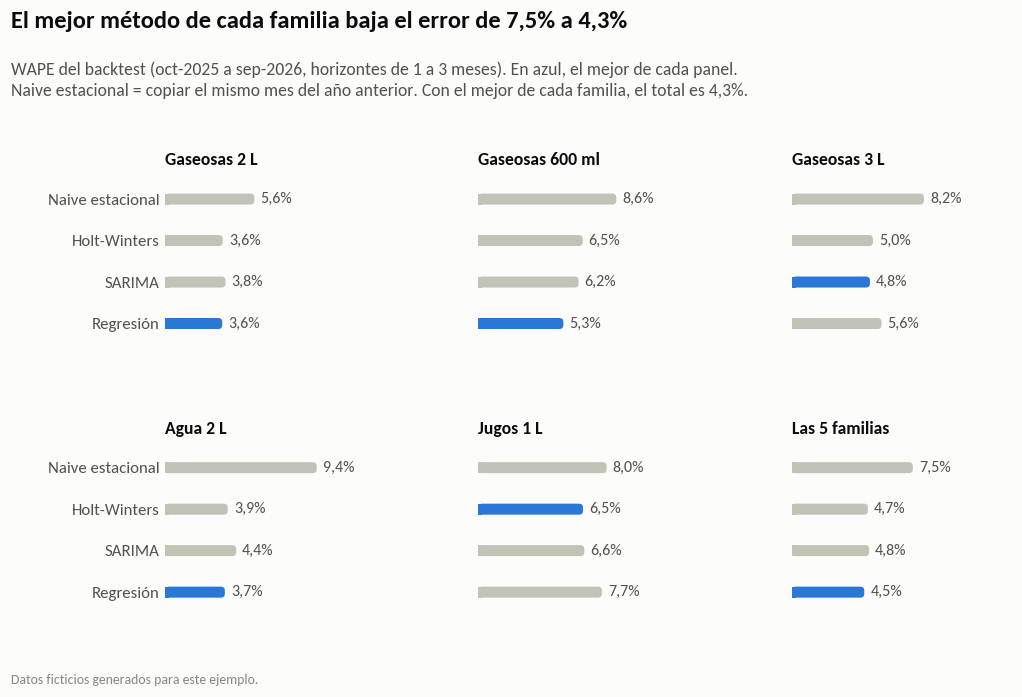

In [14]:
paneles = FAMILIAS + ["Las 5 familias"]
tope = max(wape.max().max(), total_metodo["wape"].max()) * 1.45
fig = plt.figure(figsize=(10, 6.6))
g.encabezado(fig, f"El mejor método de cada familia baja el error de {g.porcentaje(wape_base, 1)} a {g.porcentaje(wape_mejor, 1)}",
             "WAPE del backtest (oct-2025 a sep-2026, horizontes de 1 a 3 meses). En azul, el mejor de cada panel.\n"
             f"Naive estacional = copiar el mismo mes del año anterior. Con el mejor de cada familia, el total es {g.porcentaje(wape_mejor, 1)}.")
for i, panel in enumerate(paneles):
    fila, columna = divmod(i, 3)
    ax = fig.add_axes((0.16 + columna * 0.285, 0.49 - fila * 0.37, 0.20, 0.24))
    valores = (wape.loc[panel] if panel in FAMILIAS else total_metodo["wape"]).to_numpy()
    colores = [g.AZUL if v == valores.min() else g.GRIS for v in valores]
    g.barras_horizontales(ax, list(METODOS), valores, colores, grosor_px=11, x_max=tope,
                          textos=[g.porcentaje(v, 1) for v in valores])
    ax.set_title(panel, loc="left", fontsize=11.5, color=g.TINTA, fontweight="bold", pad=6)
    if columna > 0:
        ax.tick_params(labelleft=False)
g.pie(fig)
g.guardar(fig, IMG / "03_wape_por_metodo.png")

### El último año, mes a mes

Pronóstico a un mes de la familia principal, con el método base y con el mejor método, contra la venta real. Los errores están en %.

In [15]:
metodo_principal = mejor[PRINCIPAL]
principal_h1 = backtest[(backtest["familia"] == PRINCIPAL) & (backtest["h"] == 1)]
wape_principal_h1 = metricas(principal_h1, "metodo")["wape"]
comparacion = principal_h1.pivot(index="objetivo", columns="metodo", values="pronostico")[["Naive estacional", metodo_principal]]
comparacion["real"] = principal_h1.groupby("objetivo")["real"].first()
comparacion["error_base_%"] = en_porcentaje(comparacion["Naive estacional"] / comparacion["real"] - 1)
comparacion["error_mejor_%"] = en_porcentaje(comparacion[metodo_principal] / comparacion["real"] - 1)
comparacion.index = comparacion.index.strftime("%Y-%m")
comparacion

metodo,Naive estacional,Regresión,real,error_base_%,error_mejor_%
objetivo,,,,,
2025-10,"208,551.0","216,028.7",225124,-7.4,-4.0
2025-11,"221,231.0","227,577.1",230136,-3.9,-1.1
2025-12,"258,074.0","275,217.5",284534,-9.3,-3.3
2026-01,"238,121.0","242,579.0",241319,-1.3,0.5
2026-02,"250,881.0","265,907.3",261931,-4.2,1.5
2026-03,"236,289.0","221,990.6",211475,11.7,5.0
2026-04,"202,809.0","203,759.9",201945,0.4,0.9
2026-05,"180,994.0","192,095.1",184714,-2.0,4.0
2026-06,"167,439.0","174,423.3",183010,-8.5,-4.7


PosixPath('img/04_backtest.png')

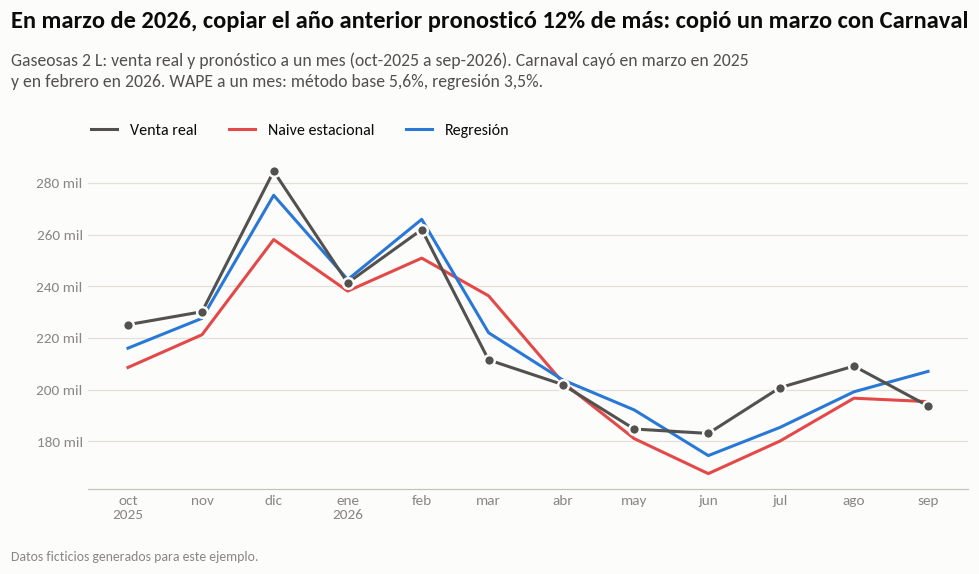

In [16]:
error_marzo = comparacion.loc["2026-03", "error_base_%"] / 100
fig, ax = g.figura(alto=5.4, ejes=(0.09, 0.15, 0.80, 0.56))
g.encabezado(fig, f"En marzo de 2026, copiar el año anterior pronosticó {g.porcentaje(error_marzo)} de más: copió un marzo con Carnaval",
             f"{PRINCIPAL}: venta real y pronóstico a un mes (oct-2025 a sep-2026). Carnaval cayó en marzo en 2025\n"
             f"y en febrero en 2026. WAPE a un mes: método base {g.porcentaje(wape_principal_h1['Naive estacional'], 1)}, "
             f"{metodo_principal.lower()} {g.porcentaje(wape_principal_h1[metodo_principal], 1)}.")
x = pd.to_datetime(comparacion.index).to_numpy()
for columna, color, nombre in [("real", g.TINTA_2, "Venta real"), ("Naive estacional", g.ROJO, "Naive estacional"),
                               (metodo_principal, g.AZUL, metodo_principal)]:
    ax.plot(x, comparacion[columna], color=color, linewidth=2, label=nombre, zorder=3 if columna == "real" else 2)
for xi, yi in zip(x, comparacion["real"]):
    marcador(ax, xi, yi, g.TINTA_2, tamanio=7)
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.79), ncols=3, fontsize=10.5, handlelength=1.6)
eje_cajas(ax)
ax.set_xticks(x)
ax.set_xticklabels([MESES[f.month - 1] + (f"\n{f.year}" if f.month in (1, 10) else "") for f in pd.to_datetime(comparacion.index)])
ax.spines["bottom"].set_color(g.EJE)
g.pie(fig)
g.guardar(fig, IMG / "04_backtest.png")

## 6. Pronóstico de octubre de 2026 a septiembre de 2027

Cada familia se pronostica con su mejor método, entrenado con toda la historia (limpia de la pandemia). Los intervalos del 80% salen de 4.000 trayectorias simuladas. Para el trimestre se suman las trayectorias mes a mes, así el intervalo del total es correcto (no es la suma de los límites de cada mes).

In [17]:
HORIZONTE = 12
tablas, trimestre = [], {}
for familia in FAMILIAS:
    pronostico, trayectorias = pronosticar(mejor[familia], cajas[familia], HORIZONTE, simulaciones=4000, semilla=1)
    tablas.append(pd.DataFrame({
        "periodo": pronostico.index.strftime("%Y-%m"), "familia": familia, "metodo": mejor[familia],
        "pronostico_cajas": pronostico.to_numpy(),
        "limite_inferior_80": trayectorias.quantile(0.10, axis=1).to_numpy(),
        "limite_superior_80": trayectorias.quantile(0.90, axis=1).to_numpy()}))
    suma_trimestre = trayectorias.iloc[:3].sum()
    trimestre[familia] = dict(metodo=mejor[familia], pronostico=pronostico.iloc[:3].sum(),
                              inferior_80=suma_trimestre.quantile(0.10), superior_80=suma_trimestre.quantile(0.90),
                              mismo_trimestre_2025=cajas.loc["2025-10-01":"2025-12-01", familia].sum())

pronostico_12m = pd.concat(tablas, ignore_index=True)
columnas_cajas = ["pronostico_cajas", "limite_inferior_80", "limite_superior_80"]
pronostico_12m[columnas_cajas] = pronostico_12m[columnas_cajas].round().astype(int)
pronostico_12m.to_csv(RESULTADOS / "pronostico_proximos_12_meses.csv", index=False)
print(f"Guardado: resultados/pronostico_proximos_12_meses.csv ({len(pronostico_12m)} filas)")
pronostico_12m.pivot(index="periodo", columns="familia", values="pronostico_cajas")[FAMILIAS]

Guardado: resultados/pronostico_proximos_12_meses.csv (60 filas)


familia,Gaseosas 2 L,Gaseosas 600 ml,Gaseosas 3 L,Agua 2 L,Jugos 1 L
periodo,,,,,
2026-10,224225,154661,72403,119263,31423
2026-11,234815,163191,74295,126473,33707
2026-12,284728,200233,97616,161173,38289
2027-01,249267,164226,78905,135473,34000
2027-02,273031,168054,91674,138151,33887
2027-03,226736,152776,71518,121590,30511
2027-04,209624,143215,66210,116887,31214
2027-05,197436,129513,62343,105212,29769
2027-06,181421,121057,53472,99805,29365


In [18]:
trimestre = pd.DataFrame.from_dict(trimestre, orient="index")
trimestre["variacion_vs_2025_%"] = en_porcentaje(trimestre["pronostico"] / trimestre["mismo_trimestre_2025"] - 1)
total_trimestre = trimestre["pronostico"].sum()
total_2025 = trimestre["mismo_trimestre_2025"].sum()
variacion_total = total_trimestre / total_2025 - 1
print(f"Octubre a diciembre de 2026: {g.miles(total_trimestre)} cajas en total, "
      f"{signo(variacion_total)} frente a oct-dic 2025 ({g.miles(total_2025)} cajas)")
columnas_trimestre = ["pronostico", "inferior_80", "superior_80", "mismo_trimestre_2025"]
trimestre.assign(**{c: trimestre[c].round().astype(int) for c in columnas_trimestre})

Octubre a diciembre de 2026: 2.016.498 cajas en total, +3,2% frente a oct-dic 2025 (1.954.218 cajas)


,metodo,pronostico,inferior_80,superior_80,mismo_trimestre_2025,variacion_vs_2025_%
Gaseosas 2 L,Regresión,743768,719230,771150,739794,0.5
Gaseosas 600 ml,Regresión,518086,495560,543482,502567,3.1
Gaseosas 3 L,SARIMA,244314,230476,259484,244687,-0.2
Agua 2 L,Regresión,406909,388989,427030,365976,11.2
Jugos 1 L,Holt-Winters,103420,95963,111408,101194,2.2


PosixPath('img/05_pronostico.png')

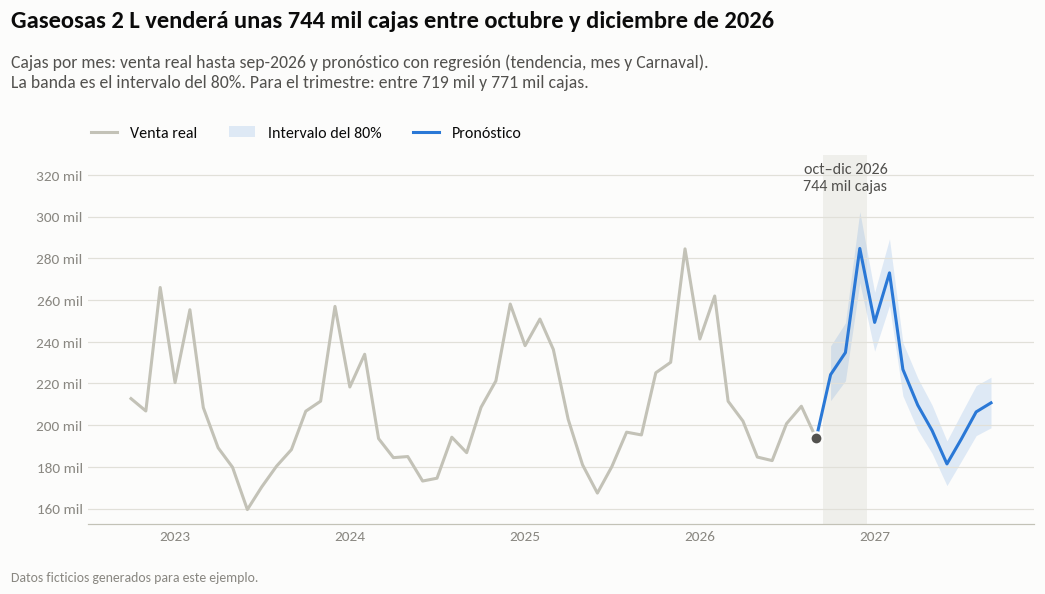

In [19]:
principal = pronostico_12m[pronostico_12m["familia"] == PRINCIPAL].copy()
principal.index = pd.to_datetime(principal["periodo"], format="%Y-%m")
historia = cajas.loc["2022-10-01":, PRINCIPAL]
q = trimestre.loc[PRINCIPAL]

fig, ax = g.figura(alto=5.6, ejes=(0.09, 0.12, 0.86, 0.60))
g.encabezado(fig, f"{PRINCIPAL} venderá unas {cajas_texto(q['pronostico'])} entre octubre y diciembre de 2026",
             f"Cajas por mes: venta real hasta sep-2026 y pronóstico con {q['metodo'].lower()} (tendencia, mes y Carnaval).\n"
             f"La banda es el intervalo del 80%. Para el trimestre: entre {cantidad(q['inferior_80'])} y {cajas_texto(q['superior_80'])}.")
ax.axvspan(pd.Timestamp("2026-09-16"), pd.Timestamp("2026-12-16"), color=g.GRILLA, alpha=0.45, linewidth=0, zorder=0)
ax.plot(historia.index.to_numpy(), historia.to_numpy(), color=g.GRIS, linewidth=2, label="Venta real")
ax.fill_between(principal.index.to_numpy(), principal["limite_inferior_80"], principal["limite_superior_80"],
                color=g.AZUL, alpha=0.14, linewidth=0, label="Intervalo del 80%")
x_futuro = np.concatenate([[historia.index[-1].to_datetime64()], principal.index.to_numpy()])
ax.plot(x_futuro, np.concatenate([[historia.iloc[-1]], principal["pronostico_cajas"]]), color=g.AZUL, linewidth=2,
        label="Pronóstico")
marcador(ax, historia.index[-1], historia.iloc[-1], g.TINTA_2)
techo = principal["limite_superior_80"].max() * 1.09
ax.set_ylim(top=techo)
ax.text(pd.Timestamp("2026-11-01"), techo * 0.99, f"oct–dic 2026\n{cajas_texto(q['pronostico'])}",
        ha="center", va="top", fontsize=10.5, color=g.TINTA_2, linespacing=1.3)
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.79), ncols=3, fontsize=10.5, handlelength=1.6)
eje_cajas(ax)
eje_anios(ax, "2023-01-01", "2027-01-01")
g.pie(fig)
g.guardar(fig, IMG / "05_pronostico.png")

## 7. ¿Cuánto vale pronosticar mejor?

El **stock de seguridad** es el inventario extra que se guarda para no quedarse sin producto cuando la venta supera el pronóstico. Depende del tamaño del error:

**Stock de seguridad = z × σ del error × √(tiempo de reposición)**

Si el pronóstico se equivoca menos, hace falta menos stock de seguridad para el mismo nivel de servicio. Ese inventario que sobra es plata inmovilizada y cuesta mantenerlo.

Supuestos (conservadores, editables en la celda siguiente):

| Supuesto | Valor | Por qué |
|---|---|---|
| Nivel de servicio | 95% (z = 1,645) | No quedarse sin stock en 19 de cada 20 ciclos de reposición. |
| σ del error | raíz del error cuadrático medio del pronóstico a un mes, en el backtest | Es el error con el que se planifica la producción del mes siguiente. |
| Tiempo de reposición | 0,5 meses (unos 15 días) | Desde que se decide producir hasta que el producto llega al almacén. Un tiempo más largo daría un ahorro mayor. |
| Costo por caja | 60% del precio neto promedio de los últimos 12 meses | Aproxima el costo de producción; conviene reemplazarlo por el costo estándar de Costos. |
| Costo de mantener inventario | 20% anual del costo por caja | Capital inmovilizado, almacén, manipuleo y mermas. Suele estar entre 20% y 30%; se toma el extremo bajo. |

In [20]:
NIVEL_SERVICIO = 0.95
Z = norm.ppf(NIVEL_SERVICIO)
REPOSICION_MESES = 0.5
COSTO_SOBRE_PRECIO = 0.60
COSTO_MANTENER_ANUAL = 0.20

a_un_mes = backtest[backtest["h"] == 1]
sigma = (a_un_mes["error"] ** 2).groupby([a_un_mes["familia"], a_un_mes["metodo"]]).mean().pow(0.5).unstack()

stock = pd.DataFrame({"metodo_elegido": mejor, "sigma_base": sigma.loc[FAMILIAS, "Naive estacional"],
                      "sigma_mejor": [sigma.loc[f, mejor[f]] for f in FAMILIAS]}, index=FAMILIAS)
stock["stock_base_cajas"] = Z * stock["sigma_base"] * np.sqrt(REPOSICION_MESES)
stock["stock_mejor_cajas"] = Z * stock["sigma_mejor"] * np.sqrt(REPOSICION_MESES)
stock["cajas_menos"] = stock["stock_base_cajas"] - stock["stock_mejor_cajas"]
stock["costo_por_caja_bs"] = COSTO_SOBRE_PRECIO * precio_actual
stock["inventario_liberado_bs"] = stock["cajas_menos"] * stock["costo_por_caja_bs"]
stock["ahorro_anual_bs"] = stock["inventario_liberado_bs"] * COSTO_MANTENER_ANUAL

totales = stock[["stock_base_cajas", "stock_mejor_cajas", "cajas_menos", "inventario_liberado_bs", "ahorro_anual_bs"]].sum()
print(f"z = {g.miles(Z, 3)} | stock de seguridad: {g.miles(totales['stock_base_cajas'])} cajas con el método base y "
      f"{g.miles(totales['stock_mejor_cajas'])} con el mejor método ({g.miles(totales['cajas_menos'])} cajas menos)")
print(f"Inventario liberado: {g.bs(totales['inventario_liberado_bs'])} | "
      f"ahorro en costo de mantenerlo: {g.bs(totales['ahorro_anual_bs'])} al año")
stock.round(1)

z = 1,645 | stock de seguridad: 60.999 cajas con el método base y 34.784 con el mejor método (26.215 cajas menos)
Inventario liberado: Bs 698.958 | ahorro en costo de mantenerlo: Bs 139.792 al año


,metodo_elegido,sigma_base,sigma_mejor,stock_base_cajas,stock_mejor_cajas,cajas_menos,costo_por_caja_bs,inventario_liberado_bs,ahorro_anual_bs
Gaseosas 2 L,Regresión,"14,846.5","8,901.5","17,267.7","10,353.2","6,914.5",31.6,"218,582.6","43,716.5"
Gaseosas 600 ml,Regresión,"14,849.9","9,347.1","17,271.7","10,871.5","6,400.2",27.7,"177,183.3","35,436.7"
Gaseosas 3 L,SARIMA,"7,467.7","4,349.7","8,685.5","5,059.1","3,626.5",30.4,"110,308.8","22,061.8"
Agua 2 L,Regresión,"12,526.1","4,886.5","14,569.0","5,683.5","8,885.5",19.4,"172,507.5","34,501.5"
Jugos 1 L,Holt-Winters,"2,755.8","2,421.7","3,205.3","2,816.6",388.6,52.4,"20,375.4","4,075.1"


### Diciembre: el costo de quedarse corto

El ahorro anterior solo cuenta el inventario. Falta el otro lado: si la venta supera al pronóstico más el stock de seguridad, hay quiebre de stock y esa venta se pierde. Diciembre es el mes más grande del año. Se revisa qué habría pasado en diciembre de 2025 si se producía el pronóstico a un mes más el stock de seguridad de cada método. Cada caja que falta se valora a su margen (precio menos costo, 40% del precio).

In [21]:
diciembre = a_un_mes[a_un_mes["objetivo"] == pd.Timestamp("2025-12-01")].set_index(["familia", "metodo"])

def faltante(metodos, columna_stock):
    """Cajas que faltan si se produce el pronóstico a un mes más el stock de seguridad."""
    filas = diciembre.loc[list(zip(FAMILIAS, metodos))]
    disponible = filas["pronostico"].to_numpy() + stock[columna_stock].to_numpy()
    return np.maximum(0, filas["real"].to_numpy() - disponible)

quiebre = pd.DataFrame({
    "faltante_base_cajas": faltante(["Naive estacional"] * len(FAMILIAS), "stock_base_cajas"),
    "faltante_mejor_cajas": faltante(mejor[FAMILIAS].tolist(), "stock_mejor_cajas"),
}, index=FAMILIAS)
margen_por_caja = (1 - COSTO_SOBRE_PRECIO) * precio_actual
quiebre["margen_perdido_base_bs"] = quiebre["faltante_base_cajas"] * margen_por_caja
quiebre["margen_perdido_mejor_bs"] = quiebre["faltante_mejor_cajas"] * margen_por_caja
faltantes = quiebre.sum()
print(f"Diciembre de 2025: faltaban {g.miles(faltantes['faltante_base_cajas'])} cajas con el método base "
      f"({g.bs(faltantes['margen_perdido_base_bs'])} de margen) y {g.miles(faltantes['faltante_mejor_cajas'])} con el mejor "
      f"({g.bs(faltantes['margen_perdido_mejor_bs'])})")
quiebre.round().astype(int)

Diciembre de 2025: faltaban 14.879 cajas con el método base (Bs 272.807 de margen) y 1.205 con el mejor (Bs 24.432)


,faltante_base_cajas,faltante_mejor_cajas,margen_perdido_base_bs,margen_perdido_mejor_bs
Gaseosas 2 L,9192,0,193724,0
Gaseosas 600 ml,0,0,0,0
Gaseosas 3 L,747,1205,15157,24432
Agua 2 L,4939,0,63926,0
Jugos 1 L,0,0,0,0


Es un solo mes, así que es un ejemplo y no una estimación anual. Sugiere que el ahorro de inventario es la parte chica del valor: el método base se queda corto justo en el mes en que más se vende.

PosixPath('img/06_stock_seguridad.png')

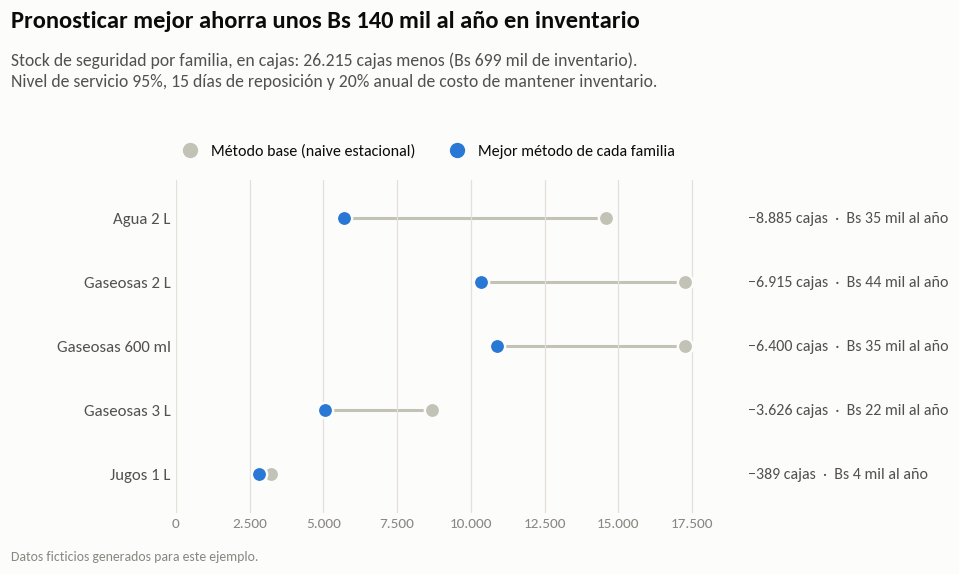

In [22]:
orden = stock.sort_values("cajas_menos", ascending=False)
fig, ax = g.figura(alto=5.4, ejes=(0.17, 0.11, 0.50, 0.56))
g.encabezado(fig, f"Pronosticar mejor ahorra unos {g.bs_compacto(totales['ahorro_anual_bs'])} al año en inventario",
             f"Stock de seguridad por familia, en cajas: {g.miles(totales['cajas_menos'])} cajas menos "
             f"({g.bs_compacto(totales['inventario_liberado_bs'])} de inventario).\n"
             f"Nivel de servicio 95%, 15 días de reposición y 20% anual de costo de mantener inventario.")
posiciones = np.arange(len(orden))[::-1]
for y, (familia, fila) in zip(posiciones, orden.iterrows()):
    ax.plot([fila["stock_mejor_cajas"], fila["stock_base_cajas"]], [y, y], color=g.GRIS, linewidth=2, zorder=1)
    marcador(ax, fila["stock_base_cajas"], y, g.GRIS, tamanio=10)
    marcador(ax, fila["stock_mejor_cajas"], y, g.AZUL, tamanio=10)
    ax.text(1.04, y, f"−{g.miles(fila['cajas_menos'])} cajas  ·  {g.bs_compacto(fila['ahorro_anual_bs'])} al año",
            transform=ax.get_yaxis_transform(), fontsize=10.5, color=g.TINTA_2, va="center")
ax.set_yticks(posiciones)
ax.set_yticklabels(orden.index)
ax.set_ylim(-0.6, len(orden) - 0.4)
ax.set_xlim(0, orden["stock_base_cajas"].max() * 1.08)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: g.miles(v)))
ax.grid(axis="x")
ax.spines["bottom"].set_visible(False)
leyenda = [plt.Line2D([], [], marker="o", linestyle="", color=c, markersize=9, label=t)
           for c, t in [(g.GRIS, "Método base (naive estacional)"), (g.AZUL, "Mejor método de cada familia")]]
fig.legend(handles=leyenda, loc="upper left", bbox_to_anchor=(0.155, 0.755), ncols=2, fontsize=10.5,
           handletextpad=0.3, columnspacing=1.6)
g.pie(fig)
g.guardar(fig, IMG / "06_stock_seguridad.png")

## 8. ¿Qué hacer primero?

In [23]:
con_regresion = [f for f in FAMILIAS if mejor[f] == "Regresión"]
ahorro_regresion = stock.loc[con_regresion, "ahorro_anual_bs"].sum()
cajas_regresion = stock.loc[con_regresion, "cajas_menos"].sum()
diciembre_2026 = pronostico_12m[pronostico_12m["periodo"] == "2026-12"].set_index("familia")
carnaval_2027 = carnaval_anual.loc[2027]

print("1) Cambiar el método antes de planificar diciembre.")
print(f"   Usar la regresión en {lista(con_regresion)}: concentran {g.porcentaje(ahorro_regresion / totales['ahorro_anual_bs'])} "
      f"del ahorro ({g.miles(cajas_regresion)} cajas menos de stock de seguridad).")
print(f"   Diciembre de 2026 debería cerrar en unas {cajas_texto(diciembre_2026['pronostico_cajas'].sum())} entre las 5 familias.")
print()
print("2) Poner el calendario de Carnaval en la planificación.")
print(f"   En 2027 el sábado de Carnaval es el {carnaval_2027['sabado_carnaval'].day} de febrero: la venta extra cae en febrero, no en marzo.")
print()
print("3) Medir el error todos los meses.")
print("   Guardar el pronóstico de cada mes y compararlo con la venta real (WAPE y sesgo). Con 12 meses nuevos,")
print("   repetir el backtest: los tres métodos estadísticos están cerca y el mejor puede cambiar.")

1) Cambiar el método antes de planificar diciembre.
   Usar la regresión en Gaseosas 2 L, Gaseosas 600 ml y Agua 2 L: concentran 81% del ahorro (22.200 cajas menos de stock de seguridad).
   Diciembre de 2026 debería cerrar en unas 782 mil cajas entre las 5 familias.

2) Poner el calendario de Carnaval en la planificación.
   En 2027 el sábado de Carnaval es el 6 de febrero: la venta extra cae en febrero, no en marzo.

3) Medir el error todos los meses.
   Guardar el pronóstico de cada mes y compararlo con la venta real (WAPE y sesgo). Con 12 meses nuevos,
   repetir el backtest: los tres métodos estadísticos están cerca y el mejor puede cambiar.


## 9. Límites

- **Los datos son ficticios.** Con datos reales hay que repetir el backtest y validar los supuestos de costo con Finanzas.
- **Un solo Carnaval en marzo.** Entre 2020 y 2026, Carnaval cayó en marzo solo en 2025, así que su efecto se estima con poca información.
- **El backtest cubre 12 meses.** El σ del error sale de 12 pronósticos a un mes por familia: es una estimación con margen.
- **El ahorro es conservador.** No incluye las ventas perdidas por quiebre de stock (el ejemplo de diciembre se muestra aparte). Tampoco usa promociones, clima ni capacidad de planta, que con datos reales conviene agregar.

## 10. Cifras citadas en el resumen y en el README

In [24]:
resumen = {
    "total_trimestre": cajas_texto(total_trimestre),
    "variacion_trimestre": f"{g.porcentaje(abs(variacion_total), 1)} {'más' if variacion_total >= 0 else 'menos'}",
    "principal_trimestre": cajas_texto(trimestre.loc[PRINCIPAL, "pronostico"]),
    "principal_inferior": cantidad(trimestre.loc[PRINCIPAL, "inferior_80"]),
    "principal_superior": cajas_texto(trimestre.loc[PRINCIPAL, "superior_80"]),
    "metodos_elegidos": "; ".join(f"{m} en {lista(mejor[mejor == m].index)}" for m in mejor.unique()),
    "wape_base": g.porcentaje(wape_base, 1),
    "wape_mejor": g.porcentaje(wape_mejor, 1),
    "menos_error": g.porcentaje(1 - wape_mejor / wape_base),
    "cajas_menos": g.miles(totales["cajas_menos"]),
    "inventario_liberado": g.bs(totales["inventario_liberado_bs"]),
    "ahorro_anual": g.bs(totales["ahorro_anual_bs"]),
    "faltante_base": g.miles(faltantes["faltante_base_cajas"]),
    "margen_perdido_base": g.bs(faltantes["margen_perdido_base_bs"]),
    "faltante_mejor": g.miles(faltantes["faltante_mejor_cajas"]),
    "margen_perdido_mejor": g.bs(faltantes["margen_perdido_mejor_bs"]),
    "accion": (f"**Usar la regresión en {lista(con_regresion)} antes de planificar diciembre.** "
               f"Concentran el {g.porcentaje(ahorro_regresion / totales['ahorro_anual_bs'])} del ahorro "
               f"({g.miles(cajas_regresion)} cajas menos de stock de seguridad)."),
}
pd.Series(resumen).to_frame("valor")

,valor
total_trimestre,"2,02 millones de cajas"
variacion_trimestre,"3,2% más"
principal_trimestre,744 mil cajas
principal_inferior,719 mil
principal_superior,771 mil cajas
metodos_elegidos,"Regresión en Gaseosas 2 L, Gaseosas 600 ml y A..."
wape_base,"7,5%"
wape_mejor,"4,3%"
menos_error,42%
cajas_menos,26.215
